In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

In [2]:
class Value:
    def __init__(self, data, children=(), op='', label=''):
        self.data = data
        self._prev = set(children)
        self._op = op
        self._label = label
        self.grad = 0.0
        self._backward= lambda:None

    def __repr__(self) -> str:
        return f"Value(data={self.data}, grad={self.grad}, op={self._op}, label={self._label})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out= Value(self.data+other.data, (self,other), '+')

        def _backward():
            self.grad += 1.0* out.grad
            other.grad += 1.0* out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out= Value(self.data*other.data, (self,other), '*')

        def _backward():
            self.grad += other.data* out.grad
            other.grad += self.data* out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out= Value(self.data**other, (self,), '**')
        def _backward():
            self.grad += other * (self.data**(other-1))* out.grad
        out._backward = _backward
        return out

    def __truediv__(self, other):
        return self * (other**-1)

    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self*-1

    def __sub__(self, other):
        return self + (-other)

    def __radd__(self, other):
        return self + (other)

    def __rsub__(self, other):
        return other + (-self)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad+= (1- t**2)*out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(self.data), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward=_backward
        return out

    def backward(self):
        topo=[]
        visited = set()
        def build_topo(n):
            if n not in visited:
                visited.add(n)
                for child in n._prev:
                    visited.add(child)
                    build_topo(child)
                topo.append(n)
        build_topo(self)

        self.grad=1.0
        for n in reversed(topo):
            n._backward()

In [3]:
from graphviz import Digraph
def trace(root):
    node, edge = set(), set()
    def build_root(v):
        if v not in node:
            node.add(v)
            for child in v._prev:
                edge.add((child,v))
                build_root(child)
    build_root(root)
    return node, edge

In [4]:
def draw_digraph(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}, engine='dot')

    node , edge = trace(root)
    for n in node:
        uid = str(id(n))

        dot.node(name=uid, label = "{ %s | data %.4f | grad %.4f }" % (n._label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid+n._op, uid)
    for n1, n2 in edge:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return  dot

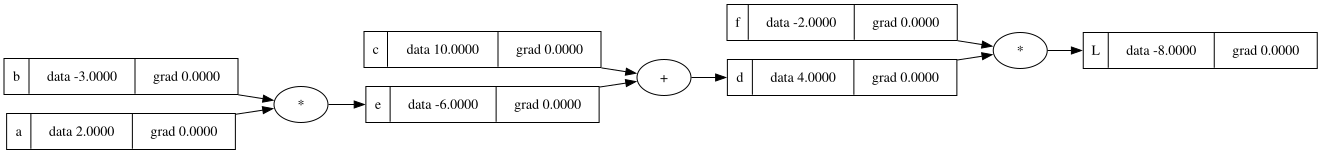

In [5]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b
e._label = 'e'
e
d = e + c
d._label = 'd'
d
f = Value(-2.0, label='f')
L = d * f;
L._label = 'L'
L
draw_digraph(L)

In [6]:
import torch

In [7]:
x1 = torch.Tensor([2.0] ).double() ; x1.requires_grad = True
x2 = torch.tensor([0.0], dtype=torch.double ) ; x2.requires_grad = True
w1 = torch.tensor([-3.0] , dtype=torch.double ) ; w1.requires_grad = True
w2 = torch.tensor([1.0] , dtype=torch.double ) ; w2.requires_grad = True
b = torch.tensor([6.8813735870195432],dtype=torch.double ) ; b.requires_grad = True
n = x1*w1 + x2*w2 +b
o = torch.tanh(n)

print(o.data.item())
o.backward()
print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071067811865476
---
x2 0.49999999999999994
w2 0.0
x1 -1.4999999999999998
w1 0.9999999999999999


In [8]:
class Neurons:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1.0, 1.0)) for _ in range(nin)]
        self.b = Value(random.uniform(-1.0, 1.0))

    def __call__(self, x):
        act = sum ((wi*xi for wi,xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters (self):
        return self.w + [self.b]

In [9]:
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neurons(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

In [10]:
class MLP:

  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [11]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.7416998203826384, grad=0.0, op=tanh, label=)

In [12]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets



In [13]:
for k in range(20):

  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

  # backward pass
  for p in n.parameters():
    p.grad = 0.0
  loss.backward()

  # update
  for p in n.parameters():
    p.data += -0.1 * p.grad

  print(k, loss.data)

0 5.298674530733872
1 5.298674530733872
2 5.298674530733872
3 5.298674530733872
4 5.298674530733872
5 5.298674530733872
6 5.298674530733872
7 5.298674530733872
8 5.298674530733872
9 5.298674530733872
10 5.298674530733872
11 5.298674530733872
12 5.298674530733872
13 5.298674530733872
14 5.298674530733872
15 5.298674530733872
16 5.298674530733872
17 5.298674530733872
18 5.298674530733872
19 5.298674530733872
